THE RULE, written before any result:
A policy PASSES if it catches at least 90% of all incidents and at least 80% of each kind while they are live,
and flags at most 5 mornings in each CLEAN year (2023 and 2024). Of the policies that pass, choose the one
with the fewest clean flags; a tie goes to the shorter median delay.

Clean world: mark noise s = 0.0963bp; fixed threshold USD 58,079

1,200 re-drawn incidents (200 of each kind, one at a time, on the clean 2024 world):
                   all WRONG_SIDE NOTIONAL   LATE MISSED  STALE BAD_PRINT delay  clean23  clean24  passes
policy                                                                                                   
PNL_FIXED        83.9%      90.0%    90.0%  67.5%  93.5%  80.0%     82.5%     0        1        5   False
PNL_SCALED       80.8%      87.0%    88.0%  63.0%  89.0%  76.5%     81.0%     0        1        0   False
SCALED+FEED      87.7%      87.0%    88.0%  63.0%  89.0% 100.0%     99.0%     0        1        0   

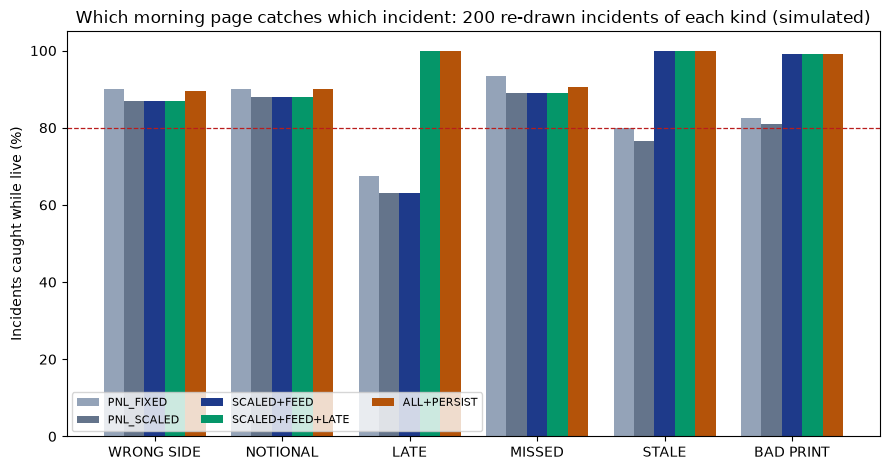

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# == Setup (done for you) ==
df = pd.read_csv(
    r'C:\Users\franklinpeng\Desktop\RDA Risk test\DataSource\rates_desk_feed.csv',
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


def positions_history(blotter=BLOTTER):
    """Done for you (Task 1's book_on, for every day at once): the position in each bond (days x bonds, USD m
    face) at each close. Each blotter row changes its ticket's face from that row's booked date onwards."""
    b = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face'])
    step = b['face'] - b.groupby('ticket')['face'].shift(1).fillna(0)
    Q = np.zeros((len(DATES), len(IDS)))
    for r, bond, s in zip(DATES.searchsorted(pd.to_datetime(b['booked'])), b['bond'], step):
        Q[r:, IDS.index(bond)] += s
    return Q


def history(curves):
    """Done for you (Task 1's price_and_ladder, for every day and bond at once). Per 100 face, rows = days, columns =
    bonds: V = value off curve t on day t; VA = value off curve t-1 on day t (the bond one day OLDER, on YESTERDAY's
    curve); K, KA = the key-rate ladders of the same two (days x bonds x 11); CASH = what the bond paid in (t-1, t]."""
    prev = np.vstack([curves[:1], curves[:-1]])
    out = {k: [] for k in ('V', 'VA', 'K', 'KA', 'CASH')}
    for bond in IDS:
        dates, cf = cash_flows(bond)
        tau = (dates.values[None, :] - DATES.values[:, None]) / np.timedelta64(1, 'D') / 365.0
        live = tau > 0
        W = interp_weights(np.where(live, tau, 1.0))
        for name, C in (('', curves), ('A', prev)):
            dfac = np.where(live, np.exp(-np.einsum('nmk,nk->nm', W, C) / 100 * tau), 0.0)
            out['V' + name].append(dfac @ cf)
            out['K' + name].append(np.einsum('nm,nmk->nk', dfac * cf * tau, W) * 1e-4)
        paid = (dates.values[None, :] > DATES.values[:-1, None]) & (dates.values[None, :] <= DATES.values[1:, None])
        out['CASH'].append(np.concatenate([[0.0], paid.astype(float) @ cf]))
    return {k: np.stack(v, axis=1) for k, v in out.items()}


UNIT = 1e4    # USD per (USD m face x price per 100): a position's USD value = face x UNIT x value per 100

INCIDENT_LOG = [   # the operations review of 2024, written after year-end: the GRADING KEY, never an input to a screen
    # first / last = the report mornings the incident could show on (a booking error held overnight from day s shows
    # in the P&L of morning s + 1 onwards; a feed fault shows on its own mornings)
    {'id': 'I1', 'kind': 'WRONG_SIDE', 'first': '2024-04-11', 'last': '2024-04-16', 'bond': 'GOV_34', 'error_m': +100,
     'what': 'T019 was a SALE of 50m GOV_34, booked as a purchase; amended 2024-04-16'},
    {'id': 'I2', 'kind': 'NOTIONAL', 'first': '2024-06-13', 'last': '2024-06-26', 'bond': 'GOV_27B', 'error_m': +36,
     'what': 'T021 bought 4m GOV_27B, booked as 40m; amended 2024-06-26'},
    {'id': 'I3', 'kind': 'LATE', 'first': '2024-09-10', 'last': '2024-09-12', 'bond': 'GOV_29B', 'error_m': -8,
     'what': 'T023 bought 8m GOV_29B on 2024-09-09, booked 2024-09-12'},
    {'id': 'I4', 'kind': 'MISSED', 'first': '2024-10-16', 'last': '2024-12-31', 'bond': 'GOV_33', 'error_m': -60,
     'what': 'T024 bought back 60m GOV_33 (closing the short) on 2024-10-15; never reached the risk system'},
    {'id': 'I5', 'kind': 'STALE', 'first': '2024-07-16', 'last': '2024-07-26', 'bond': None, 'error_m': 0,
     'what': 'Z_1Y frozen at its 2024-07-15 value on 8 mornings, 2024-07-16 to 2024-07-25'},
    {'id': 'I6', 'kind': 'BAD_PRINT', 'first': '2024-11-20', 'last': '2024-11-21', 'bond': None, 'error_m': 0,
     'what': 'Z_5Y printed 31bp too high on 2024-11-20 only'},
]   # error_m = booked minus true position, USD m face, while the incident lasts
MISSING_TICKETS = [('T024', '2024-10-15', '2024-10-15', 'GOV_33', 60)]
CORRECTIONS = {   # the vendor's corrected values for the faulty feed points: (date, column): zero yield %
    ('2024-07-16', 'Z_1Y'): 4.7904, ('2024-07-17', 'Z_1Y'): 4.7981, ('2024-07-18', 'Z_1Y'): 4.7587,
    ('2024-07-19', 'Z_1Y'): 4.7402, ('2024-07-22', 'Z_1Y'): 4.6895, ('2024-07-23', 'Z_1Y'): 4.6907,
    ('2024-07-24', 'Z_1Y'): 4.6368, ('2024-07-25', 'Z_1Y'): 4.7069, ('2024-11-20', 'Z_5Y'): 4.4186,
}


def corrected_blotter():
    """Done for you: every ticket as finally amended, effective from its TRADED date, plus the tickets the risk
    system never received. This is the true book."""
    last = {}
    for row in BLOTTER + MISSING_TICKETS:
        last[row[0]] = row
    return [(t, traded, traded, bond, face) for (t, booked, traded, bond, face) in last.values()]


def corrected_feed():
    """Done for you: the curve feed with the vendor's corrections applied."""
    Zc = Z.copy()
    for (day, col), v in CORRECTIONS.items():
        Zc[DATES.get_loc(pd.Timestamp(day)), LAB.index(col[2:])] = v
    return Zc


def feed_flags(curves, tol=0.0002, min_len=3, limit_bp=8.0):
    """Done for you (Task 4's two feed screens, one flag per day): STALE on the morning a vertex completes its
    min_len-th tiny move in a row, KINK on a morning an inner vertex's kink jumps by more than limit_bp."""
    small = np.vstack([np.zeros((1, 11), bool), np.abs(np.diff(curves, axis=0)) < tol])
    run = small.copy()
    for lag in range(1, min_len):
        run[lag:] &= small[:-lag]
        run[:lag] = False
    w = (TEN[1:-1] - TEN[:-2]) / (TEN[2:] - TEN[:-2])
    kink = curves[:, 1:-1] - ((1 - w) * curves[:, :-2] + w * curves[:, 2:])
    dk = np.vstack([np.zeros((1, 9)), np.diff(kink, axis=0) * 100])
    return run.any(axis=1), (np.abs(dk) > limit_bp).any(axis=1)


POLICIES = {   # which signals each candidate morning page ORs together
    'PNL_FIXED': ['pnl_fixed'],
    'PNL_SCALED': ['pnl_scaled'],
    'SCALED+FEED': ['pnl_scaled', 'stale', 'kink'],
    'SCALED+FEED+LATE': ['pnl_scaled', 'stale', 'kink', 'late'],
    'ALL+PERSIST': ['pnl_scaled', 'stale', 'kink', 'late', 'persist'],
}
RULE = ("A policy PASSES if it catches at least 90% of all incidents and at least 80% of each kind while they are live,\n"
        "and flags at most 5 mornings in each CLEAN year (2023 and 2024). Of the policies that pass, choose the one\n"
        "with the fewest clean flags; a tie goes to the shorter median delay.")


def persistence(z, days=5):
    """TODO: Sum of z squared over the last `days` mornings (fewer at the start of the series): a run of medium gaps adds up
    even when no single morning crosses 3.5. Use a cumulative sum: c[i] - c[i - days]."""
    squared = np.asarray(z, dtype=float) ** 2
    c = np.concatenate(([0.0], np.cumsum(squared)))

    end = np.arange(1, len(z) + 1)
    start = np.maximum(0, end - days)

    return c[end] - c[start]


def policy_flags(name, sig):
    """TODO: The mornings policy `name` flags: the OR of the boolean arrays in `sig` named by POLICIES[name]."""
    keys = POLICIES[name]

    flags = np.zeros_like(sig[keys[0]], dtype=bool)

    for key in keys:
        flags |= sig[key]

    return flags


def caught(flags, first, last):
    """TODO: (True, delay) if any morning first..last (indices, inclusive) is flagged, delay = mornings from `first` to the
    first flag; (False, None) if none is."""
    hits = np.flatnonzero(flags[first:last + 1])

    if len(hits) > 0:
        return True, int(hits[0])

    return False, None


# ---------------------------------------------------------------------------
Zc = corrected_feed()
H = history(Zc)
Q = positions_history(corrected_blotter()) * UNIT       # the TRUE book on the corrected feed = the clean world
moves = np.vstack([np.zeros((1, 11)), np.diff(Zc, axis=0) * 100])
Qp = np.vstack([Q[:1], Q[:-1]])
Kp = np.vstack([H['K'][:1], H['K'][:-1]])
L_prev = np.einsum('nb,nbk->nk', Qp, Kp)
unit_pred = UNIT * (H['VA'] + H['CASH'] - np.vstack([H['V'][:1], H['V'][:-1]]) - np.einsum('nbk,nk->nb', Kp, moves))
U_clean = PNL - (Qp / UNIT * unit_pred).sum(1)           # what is left is mark noise (plus a little convexity)
y23, y24 = REP[DATES[REP].year == 2023], REP[DATES[REP].year == 2024]
g2 = np.sqrt((L_prev ** 2).sum(1))
s = float(np.std(U_clean[y23]) / np.sqrt(2 * np.mean(g2[y23] ** 2)))
FIXED = 3.5 * np.std(U_clean[y23])
checks = [('persistence', lambda: persistence(np.ones(8))),
          ('policy_flags', lambda: policy_flags('PNL_FIXED', {'pnl_fixed': np.zeros(3, bool)})),
          ('caught', lambda: caught(np.zeros(5, bool), 1, 3))]
todo = next((name for name, f in checks if f() is None), None)
if todo:
    print(f"Fill in the TODOs above, then run again. Next: {todo}()")
else:
    print("THE RULE, written before any result:\n" + RULE)
    stale0, kink0 = feed_flags(Zc)

    def signals(U, idx, stale, kink, late):
        z = U[idx] / (np.sqrt(2) * s * g2[idx])
        return {'pnl_fixed': np.abs(U[idx]) > FIXED, 'pnl_scaled': np.abs(z) > 3.5, 'stale': stale[idx],
                'kink': kink[idx], 'late': late, 'persist': persistence(z) > 20}

    clean = {yr: signals(U_clean, idx, stale0, kink0, np.zeros(len(idx), bool)) for yr, idx in ((2023, y23), (2024, y24))}
    print(f"\nClean world: mark noise s = {s:.4f}bp; fixed threshold USD {FIXED:,.0f}")

    rng = np.random.default_rng(2024)
    KINDS = ['WRONG_SIDE', 'NOTIONAL', 'LATE', 'MISSED', 'STALE', 'BAD_PRINT']
    n24 = len(y24)
    res = {p: {k: [] for k in KINDS} for p in POLICIES}
    sizes = []   # (|DV01 of the booking error| USD per bp, caught by PNL_SCALED) for the booking incidents
    for kind in KINDS:
        for _ in range(200):
            a = int(rng.integers(5, n24 - 45))                   # the incident starts at the close of morning a
            U, late = U_clean.copy(), np.zeros(n24, bool)
            stale, kink = stale0, kink0
            if kind in ('STALE', 'BAD_PRINT'):
                k = int(rng.integers(0, 11))
                Zx = Zc.copy()
                t0 = y24[a]
                n_bad = int(rng.integers(3, 11)) if kind == 'STALE' else 1
                if kind == 'STALE':
                    Zx[t0:t0 + n_bad, k] = Zc[t0 - 1, k]
                else:
                    Zx[t0, k] += rng.choice([-1, 1]) * rng.uniform(10, 40) / 100
                derr = np.vstack([np.zeros((1, 11)), np.diff(Zx - Zc, axis=0) * 100])
                U += (L_prev * derr).sum(1)                      # first order: our ladder times the feed's error
                stale, kink = feed_flags(Zx)
                first, last = a, a + n_bad                       # its own mornings + the morning it snaps back
            else:
                held = [b for b in range(len(IDS)) if Q[y24[a], b] != 0 and H['V'][y24[min(a + 45, n24 - 1)], b] > 0]
                b = int(rng.choice(held))
                F = np.sign(Q[y24[a], b]) * min(rng.uniform(5, 60), abs(Q[y24[a], b]) / UNIT)   # the ticket, USD m
                n_bad = int(rng.integers(2, 16))
                e = {'WRONG_SIDE': -2 * F, 'NOTIONAL': 9 * F if rng.random() < 0.5 else -0.9 * F,
                     'LATE': -F, 'MISSED': F}[kind]
                if kind == 'LATE':
                    n_bad = int(rng.integers(1, 6))
                    late[a + n_bad] = True                       # booked n_bad mornings late: the walk sees it then
                if kind == 'MISSED':
                    n_bad = int(rng.integers(10, 41))
                held_wrong = np.zeros(len(DATES))
                held_wrong[y24[a]:y24[a] + n_bad] = e            # booked minus true face, closes a .. a + n_bad - 1
                U -= np.concatenate([[0.0], held_wrong[:-1]]) * unit_pred[:, b]
                first, last = a + 1, a + n_bad
                err_dv01 = abs(e) * UNIT * H['K'][y24[a], b].sum()
            sig = signals(U, y24, stale, kink, late)
            for p in POLICIES:
                res[p][kind].append(caught(policy_flags(p, sig), first, last))
            if kind in ('WRONG_SIDE', 'NOTIONAL', 'MISSED'):
                sizes.append((err_dv01, res['PNL_SCALED'][kind][-1][0]))

    rows = []
    for p in POLICIES:
        allc = [c for k in KINDS for c in res[p][k]]
        delays = [d for ok, d in allc if ok]
        row = {'policy': p, 'all': np.mean([ok for ok, _ in allc])}
        row.update({k: np.mean([ok for ok, _ in res[p][k]]) for k in KINDS})
        row.update({'delay': float(np.median(delays)), 'clean23': int(policy_flags(p, clean[2023]).sum()),
                    'clean24': int(policy_flags(p, clean[2024]).sum())})
        row['passes'] = (row['all'] >= 0.90 and min(row[k] for k in KINDS) >= 0.80
                         and row['clean23'] <= 5 and row['clean24'] <= 5)
        rows.append(row)
    t = pd.DataFrame(rows).set_index('policy')
    print(f"\n{len(KINDS) * 200:,} re-drawn incidents (200 of each kind, one at a time, on the clean 2024 world):")
    pct = lambda v: f"{100 * v:.1f}%"
    print(t.to_string(formatters={**{k: pct for k in ['all'] + KINDS}, 'delay': '{:.0f}'.format}))
    ok = t[t.passes]
    if len(ok):
        win = ok.assign(clean=ok.clean23 + ok.clean24).sort_values(['clean', 'delay']).index[0]
        print(f"\nSigned off: {win} (passes; {ok.loc[win, 'clean23'] + ok.loc[win, 'clean24']} clean flags in two years)")
    else:
        print("\nNo policy passes the rule.")
    miss = [k for k in KINDS if t.loc['PNL_SCALED', k] < 0.80]
    print("Kinds the P&L check alone catches less than 80% of: " + ', '.join(f"{k} {pct(t.loc['PNL_SCALED', k])}" for k in miss))

    sz = pd.DataFrame(sizes, columns=['dv01', 'ok'])
    sz['band'] = pd.cut(sz.dv01, [0, 2500, 10000, 40000, np.inf], labels=['under 2.5k', '2.5k-10k', '10k-40k', 'over 40k'])
    print("PNL_SCALED on the 600 booking errors (wrong side, notional, missed), by the error's DV01 (USD per bp):")
    for band, g in sz.groupby('band', observed=True):
        print(f"  {band:<11} {len(g):>4} incidents, caught {100 * g.ok.mean():.1f}%")

    fig, ax = plt.subplots(figsize=(9, 4.8))
    x = np.arange(len(KINDS))
    cols = ['#94a3b8', '#64748b', '#1e3a8a', '#059669', '#b45309']
    for j, p in enumerate(POLICIES):
        ax.bar(x + (j - 2) * 0.16, 100 * t.loc[p, KINDS].astype(float), 0.16, color=cols[j], label=p)
    ax.axhline(80, color='#b91c1c', lw=0.9, ls='--')
    ax.set_xticks(x)
    ax.set_xticklabels([k.replace('_', ' ') for k in KINDS])
    ax.set_ylabel('Incidents caught while live (%)')
    ax.set_ylim(0, 105)
    ax.set_title('Which morning page catches which incident: 200 re-drawn incidents of each kind (simulated)')
    ax.legend(fontsize=8, ncol=3, loc='lower left')
    plt.tight_layout()
    plt.show()
